# Week 5 — End-to-End Insider Threat Detection Pipeline
### Final Demonstration & Reproducibility Notebook

This notebook is a **presentation layer** over the already-verified, frozen Week-5 system.
It consumes the existing `week5/final_pipeline/*.py` implementation and the existing frozen
artifacts. **Nothing is retrained, retuned, rerun-expensive, or regenerated here.**

```
CERT r4.2 held-out test data
        ↓
Tier 1 — HTTP / File-Device / Logon / Email
        ↓
Tier 2 — LangGraph fusion + gates
        ↓
Escalated cases (712)
        ↓
Week-4 EvidenceBuilder
        ↓
Tier 3 — Qwen2.5-1.5B-Instruct
        ↓
Grounding / schema validation
        ↓
FastAPI service
```

**Facts this notebook states and demonstrates:**

* **Tier 2 makes the security escalation decision** (frozen gating).
* **Tier 3 only reasons about cases already escalated by Tier 2** — it does *not* decide
  whether a case is escalated, and it does *not* introduce a manual severity/action policy.
* Week-4 outputs are **frozen** and reused (712 calls, 0 retries, 0 fallbacks).
* Week-5 **does not retrain or retune** the system — it integrates and evaluates the frozen
  Week-1–4 system.

## 2. System Architecture

```
                    CERT r4.2 held-out test (61,203 rows, 200 users)
                       │
                       ▼
              ┌────────────────────────────┐
              │  Tier 1 — modality agents  │  frozen MLPs (204/215/20/47 features)
              │  HTTP · File/Device · Logon │  no retraining
              │  · Email                   │
              └─────────────┬──────────────┘
                            │ per-modality anomaly scores
                            ▼
              ┌────────────────────────────┐
              │  Tier 2 — LangGraph        │  FROZEN: HC 0.60, corr 0.30,
              │  fusion + gates            │  weights 50/20/15/15
              └─────────────┬──────────────┘
                            │  escalation decision lives HERE
                            ▼  escalated cases (712)
              ┌────────────────────────────┐
              │  Week-4 EvidenceBuilder    │  canonical evidence inventory
              └─────────────┬──────────────┘
                            ▼
              ┌────────────────────────────┐
              │  Tier 3 — Qwen2.5-1.5B     │  reasons ONLY about escalated cases
              │  (Ollama, frozen outputs)  │  severity/action preserved (no manual policy)
              └─────────────┬──────────────┘
                            ▼
              ┌────────────────────────────┐
              │  Grounding / schema        │  2 contracts: structural (100%)
              │  validation                │  vs strict explanation (80.9%)
              └─────────────┬──────────────┘
                            ▼
                       FastAPI /score  (service interface demo)
```

Each module is a separate file in `week5/final_pipeline/` (`tier1.py`, `tier2.py`,
`tier3.py`, `app.py`); the notebook imports them rather than re-implementing them.

## 3. Environment & Reproducibility

Runtime versions are read from the actual environment. The notebook must run even when
Ollama is unavailable — the frozen Week-4 Tier-3 outputs remain the evaluation source.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import sklearn
import fastapi
import mlflow

ROOT = Path.cwd().resolve()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
for _p in (str(ROOT), str(ROOT / "week5"), str(ROOT / "week4" / "final_llm_reasoning")):
    if _p not in sys.path:
        sys.path.insert(0, _p)

import importlib
extra = {}
for m in ("langgraph", "shap", "ollama"):
    try:
        mod = importlib.import_module(m)
        extra[m] = getattr(mod, "__version__", "available")
    except Exception:
        extra[m] = "not installed"

env = pd.DataFrame({
    "Component": ["Python", "PyTorch", "NumPy", "pandas", "scikit-learn",
                  "FastAPI", "MLflow", "LangGraph", "SHAP", "Ollama"],
    "Version": [sys.version.split()[0], torch.__version__, np.__version__,
                pd.__version__, sklearn.__version__, fastapi.__version__,
                mlflow.__version__, extra["langgraph"], extra["shap"], extra["ollama"]],
})
env

,Component,Version
0,Python,3.12.13
1,PyTorch,2.5.1+cu121
2,NumPy,2.5.1
3,pandas,2.3.3
4,scikit-learn,1.9.0
5,FastAPI,0.139.2
6,MLflow,3.14.0
7,LangGraph,available
8,SHAP,not installed
9,Ollama,available


In [2]:
from week5.final_pipeline import pipeline as P

# Ollama availability (frozen Week-4 LLM served via Ollama)
try:
    import ollama
    models = ollama.list().models
    qwen = next((m.model for m in models if "qwen2.5" in getattr(m, "model", "")), None)
    ollama_ok = qwen is not None
except Exception:
    qwen, ollama_ok = None, False

print(f"Ollama available: {ollama_ok}")
print(f"Qwen model: {qwen if ollama_ok else P.LLM_MODEL + ' (frozen config)'}")
if not ollama_ok:
    print("Ollama unavailable — live Tier-3 demonstration skipped.")
    print("Frozen Week-4 Tier-3 outputs remain available for evaluation.")

paths = pd.DataFrame({
    "Artifact": ["Tier-1 models", "Frozen Tier-2 input", "Week-4 Tier-3 outputs",
                 "Week-4 grounding results", "Week-5 outputs"],
    "Path": [str(P.TIER1_DIR), str(P.W4_FROZEN_INPUT), str(P.W4_TRIAGE_OUTPUTS),
             str(P.W4_GROUNDING_RESULTS), str(P.OUT)],
})
paths

Ollama available: True
Qwen model: qwen2.5:1.5b-instruct


C:\insider_threat_detection_project2\.venv\Lib\site-packages\torch\cuda\__init__.py:235: UserWarning: 
NVIDIA GeForce RTX 5090 with CUDA capability sm_120 is not compatible with the current PyTorch installation.
The current PyTorch install supports CUDA capabilities sm_50 sm_60 sm_61 sm_70 sm_75 sm_80 sm_86 sm_90.
If you want to use the NVIDIA GeForce RTX 5090 GPU with PyTorch, please check the instructions at https://pytorch.org/get-started/locally/

  warnings.warn(


,Artifact,Path
0,Tier-1 models,C:\insider_threat_detection_project2\tier1
1,Frozen Tier-2 input,C:\insider_threat_detection_project2\week4\fro...
2,Week-4 Tier-3 outputs,C:\insider_threat_detection_project2\week4\fin...
3,Week-4 grounding results,C:\insider_threat_detection_project2\week4\fin...
4,Week-5 outputs,C:\insider_threat_detection_project2\week5\fin...


## 4. Frozen Configuration

The frozen Tier-2 configuration is read from the implementation and verified
programmatically. If the implementation differed from the frozen contract, this cell
would report the discrepancy instead of silently changing anything.

In [3]:
cfg = pd.DataFrame({
    "Setting": ["HC threshold", "Correlation threshold",
                "Weight HTTP", "Weight File/Device", "Weight Logon", "Weight Email"],
    "Value": [P.HC_THRESHOLD, P.CORR_THRESHOLD,
              P.WEIGHTS["http"], P.WEIGHTS["file_device"],
              P.WEIGHTS["logon"], P.WEIGHTS["email"]],
})
cfg

frozen = {"HC threshold": 0.60, "Correlation threshold": 0.30,
          "Weight HTTP": 0.50, "Weight File/Device": 0.20,
          "Weight Logon": 0.15, "Weight Email": 0.15}
actual = dict(zip(cfg["Setting"], cfg["Value"]))
assert all(abs(actual[k] - v) < 1e-9 for k, v in frozen.items()), "FROZEN CONFIG MISMATCH"
print("Frozen configuration verified: HC=0.60, corr=0.30, weights 50/20/15/15.")

Frozen configuration verified: HC=0.60, corr=0.30, weights 50/20/15/15.


## 5. Dataset & Leakage Verification

The frozen held-out test population and the train/validation/test user-split
disjointness are derived from the actual files (`meta.json` + frozen Tier-2 input),
not typed in.

In [4]:
import json

t2 = pd.read_csv(P.W4_FROZEN_INPUT)
escalated = t2[t2["escalate"] == 1]

meta = {m: json.loads((P.TIER1_DIR / m / "meta.json").read_text())
        for m in ("http", "file_device", "logon", "email")}
train_u = set(meta["http"]["train_users"]); val_u = set(meta["http"]["validation_users"]); test_u = set(meta["http"]["test_users"])
for m in ("file_device", "logon", "email"):
    train_u &= set(meta[m]["train_users"]); val_u &= set(meta[m]["validation_users"]); test_u &= set(meta[m]["test_users"])

population = pd.DataFrame({
    "Quantity": ["Test rows (user-days)", "Held-out users", "Positive user-days",
                 "Tier-2 escalations", "Escalation rate", "Train users", "Validation users", "Test users"],
    "Value": [f"{len(t2):,}", f"{t2['user'].nunique():,}", f"{int(t2['label'].sum()):,}",
              f"{len(escalated):,}", f"{len(escalated)/len(t2):.4%}",
              len(train_u), len(val_u), len(test_u)],
})
population

,Quantity,Value
0,Test rows (user-days),"61,203"
1,Held-out users,200
2,Positive user-days,201
3,Tier-2 escalations,712
4,Escalation rate,1.1633%
5,Train users,600
6,Validation users,200
7,Test users,200


In [5]:
leak = pd.DataFrame({
    "Intersection": ["train ∩ validation", "train ∩ test", "validation ∩ test"],
    "count": [len(train_u & val_u), len(train_u & test_u), len(val_u & test_u)],
})
leak["disjoint"] = leak["count"] == 0
leak

assert (leak["count"] == 0).all()
print("Leakage verification PASS — train/validation/test user sets are pairwise disjoint.")

Leakage verification PASS — train/validation/test user sets are pairwise disjoint.


## 6. Tier-1 Demonstration

**Frozen Tier-1 artifacts are loaded; no retraining is performed.** Only a lightweight
structural verification plus scoring of ONE representative held-out test case.

In [6]:
from week5.final_pipeline import pipeline as P
from week5.final_pipeline import tier1 as T1

bundle = P.load_tier1()

struct = pd.DataFrame([
    {"modality": m,
     "model_input_dim": bundle["models"][m].net[0].in_features,
     "meta_input_dim": bundle["meta"][m]["input_dim"],
     "scaler_len": len(bundle["scalers"][m].mean_),
     "feature_cols": len(bundle["feature_cols"][m]),
     "seed": bundle["meta"][m]["seed"]}
    for m in P.CHANNELS])
struct
assert (struct["model_input_dim"] == struct["meta_input_dim"]).all()
assert (struct["scaler_len"] == struct["feature_cols"]).all()
print("Tier-1 structural verification PASS — model/scaler/feature dimensions aligned, feature order = model order.")

Tier-1 structural verification PASS — model/scaler/feature dimensions aligned, feature order = model order.


In [7]:
# score ONE representative held-out test case (first escalated row) — demonstration only
test_pkl = pd.read_pickle(str(P.DATA_DIR / "dayr4.2-percentile30-test.pkl"))
row = escalated.iloc[0]
feats = T1.assemble_feature_rows(test_pkl, pd.DataFrame({"user": [int(row["user"])], "day": [int(row["day"])]}), bundle)
scores = T1.score_cases(bundle, feats)
s = scores.iloc[0]

pd.DataFrame({
    "modality": P.CHANNELS,
    "score": [round(float(s[f"{m}_score"]), 4) for m in P.CHANNELS],
    "feature_dim": [len(s[f"{m}_features"]) for m in P.CHANNELS],
})

C:\insider_threat_detection_project2\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\insider_threat_detection_project2\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\insider_threat_detection_project2\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\insider_threat_detection_project2\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


,modality,score,feature_dim
0,http,0.9348,204
1,file_device,0.0078,215
2,logon,0.0762,20
3,email,0.2146,47


## 7. Tier-2 / LangGraph Demonstration

**Tier 2 is responsible for the validated security escalation decision.** The existing
LangGraph orchestrator runs the frozen gates on one representative case. No new decision
rule is introduced.

In [8]:
from week5.final_pipeline import tier2 as T2

lg = T2.graph_decision(scores.iloc[0])
pd.DataFrame({
    "field": ["fused_score", "fired_channels", "gate", "escalated",
              "degraded_channels", "degraded_mode", "rationale"],
    "value": [round(float(lg["risk_score"]), 4), lg["fired_channels"], lg["gate_triggered"],
              bool(lg["escalate"]), lg.get("degraded_channels", []),
              bool(lg.get("degraded_mode", False)), lg["rationale"]],
})

,field,value
0,fused_score,0.5126
1,fired_channels,[http]
2,gate,high_confidence
3,escalated,True
4,degraded_channels,[]
5,degraded_mode,False
6,rationale,HIGH-CONFIDENCE ESCALATION: HTTP anomaly score...


## 8. LangGraph vs Vectorized Equivalence

The real LangGraph orchestrator is compared against the vectorized reference over the
frozen population. This is a read-only check (~1 min) — no inference, no artifact writes.
The result (0 mismatches) is derived from execution.

In [9]:
res = T2.equivalence_check(t2)   # full frozen population
print(f"Rows checked: {res['n_compared']:,}")
print(f"Mismatches:   {res['n_mismatches']}")
print("Risk-score agreement: |graph − vectorized| ≤ 1e-9 (checked inside equivalence_check)")
print("Gate + escalation agreement: included in mismatch count")
assert res["n_mismatches"] == 0
print("Equivalence verified: 0 mismatches over 61,203 rows.")

Rows checked: 61,203
Mismatches:   0
Risk-score agreement: |graph − vectorized| ≤ 1e-9 (checked inside equivalence_check)
Gate + escalation agreement: included in mismatch count
Equivalence verified: 0 mismatches over 61,203 rows.


## 9. Final Tier-2 Evaluation

System metrics are **loaded from the existing artifact** `outputs/system_metrics.csv` /
`outputs/system_predictions.csv` (generated during the frozen Week-5 run) — not typed in.

In [10]:
sys_metrics = pd.read_csv(P.OUT / "system_metrics.csv")
sys_metrics["value"] = sys_metrics["value"].astype(float)
sm = dict(zip(sys_metrics["metric"], sys_metrics["value"]))

def fmt(v):
    return f"{v:,.0f}" if abs(v) >= 1 else f"{v:.4f}"

metrics_tbl = pd.DataFrame({
    "Metric": ["TP", "FP", "FN", "TN", "Recall", "Precision", "F1", "FPR",
               "ROC-AUC", "PR-AUC", "Escalations", "Escalation rate"],
    "Value": [fmt(sm["tier2_tp"]), fmt(sm["tier2_fp"]), fmt(sm["tier2_fn"]), fmt(sm["tier2_tn"]),
              f"{sm['tier2_recall']:.4f}", f"{sm['tier2_precision']:.4f}", f"{sm['tier2_f1']:.4f}",
              f"{sm['tier2_fpr']:.4f}", f"{sm['tier2_roc_auc']:.4f}", f"{sm['tier2_pr_auc']:.4f}",
              fmt(sm["tier2_escalated"]), f"{sm['tier2_escalation_rate']:.4%}"],
})
metrics_tbl

,Metric,Value
0,TP,178
1,FP,534
2,FN,23
3,TN,"60,468"
4,Recall,0.8856
5,Precision,0.2500
6,F1,0.3899
7,FPR,0.0088
8,ROC-AUC,0.9829
9,PR-AUC,0.5878


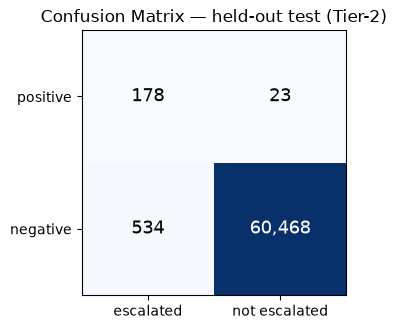

In [11]:
import matplotlib.pyplot as plt

pred = pd.read_csv(P.OUT / "system_predictions.csv")
cm = pd.crosstab(pred["label"].astype(int), pred["escalate"].astype(int)).reindex(index=[1, 0], columns=[1, 0]).fillna(0).astype(int)
cm.index = ["positive", "negative"]; cm.columns = ["escalated", "not escalated"]

fig, ax = plt.subplots(figsize=(4.5, 3.4))
im = ax.imshow(cm.values, cmap="Blues")
ax.set_xticks([0, 1], cm.columns); ax.set_yticks([0, 1], cm.index)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm.values[i, j]:,}", ha="center", va="center", fontsize=13,
                color="white" if cm.values[i, j] > cm.values.max() / 2 else "black")
ax.set_title("Confusion Matrix — held-out test (Tier-2)")
plt.tight_layout(); plt.show()

## 10. Week-4 Tier-3 Integration

The frozen Week-4 Tier-3 outputs are loaded and aligned with the Tier-2 escalations by
**(user, day)** — never by row position. No LLM call is regenerated.

In [12]:
triage = pd.read_csv(P.W4_TRIAGE_OUTPUTS)
grounding = pd.read_csv(P.W4_GROUNDING_RESULTS)

esc_keys = set(zip(escalated["user"].astype(int), escalated["day"].astype(int)))
tr_keys = set(zip(triage["user"].astype(int), triage["day"].astype(int)))

align = pd.DataFrame({
    "Check": ["Tier-2 escalations", "Tier-3 rows", "Matched (user, day)",
              "Duplicate IDs", "Missing IDs", "Extra IDs"],
    "Value": [len(esc_keys), len(triage), len(esc_keys & tr_keys),
              int(triage.duplicated(["user", "day"]).sum()),
              len(esc_keys - tr_keys), len(tr_keys - esc_keys)],
})
align
assert len(esc_keys & tr_keys) == 712 and len(esc_keys - tr_keys) == 0
print("Alignment verified: 712 / 712 matched, 0 duplicates, 0 missing, 0 extra.")

Alignment verified: 712 / 712 matched, 0 duplicates, 0 missing, 0 extra.


In [13]:
# two representative frozen Tier-3 outputs (no raw logs)
triage[["user", "day", "explanation", "severity_category", "recommended_action", "evidence_used"]].head(2)

,user,day,explanation,severity_category,recommended_action,evidence_used
0,9,365,HTTP content length is reduced (0th percentile...,high,soc_escalation,"[""HTTP_E1""]"
1,11,280,URL depth is reduced (0th percentile). Risk sc...,high,immediate_isolation,"[""HTTP_E1""]"


## 11. Grounding Validation — TWO CONTRACTS

There are **two different validation contracts**, and they are intentionally reported
separately (they are not equivalent, and the notebook does not reconcile them):

| # | Contract | Metric | Result |
|---|----------|--------|--------|
| 1 | **Week-4 structural evidence grounding** — validates the *deterministically constructed, evidence-derived observations* | validated observation rate / validated evidence-ID rate | **712/712 = 100 %** |
| 2 | **Week-5 strict natural-language explanation grounding** — runs the canonical `GroundingValidator` on each constructed explanation | strict `grounding_valid` | **576/712 = 80.9 %** |

The 136 strict failures are all `feature_grounding_valid = False`. The existing Week-4
audit establishes that these arise from the **Week-4 `evidence_used` top-1 versus
explanation top-3 evidence artifact** (the structured `evidence_used` field lists only
the top-1 evidence while the explanation cites another evidence feature). There are
**0 invalid evidence IDs, 0 invalid channels, 0 invalid observations and 0 unsupported
intent terms** in either contract.

The strict 576/712 result is **not hidden**; and it is **not claimed** that the LLM has
100 % semantic grounding. The 100 % number is structural; the 80.9 % number is strict.

In [14]:
grounding[["metric", "value"]].head(13)

,metric,value
0,n_cases,712
1,llm_calls,712
2,retries,0
3,fallbacks,0
4,fallback_reasons,{'': 712}
5,cases_with_validated_observations,712
6,validated_observation_rate,1.0
7,cases_with_validated_evidence_ids,712
8,validated_evidence_rate,1.0
9,invalid_evidence_ids_total,0


In [ ]:
# Week-5 strict re-validation (cheap, read-only; uses the canonical validator)
from week5.final_pipeline.evidence_builder import EvidenceBuilder, feature_cols_by_modality
from week5.final_pipeline.grounding_validator import GroundingValidator
import ast

cols_all = pd.read_pickle(str(P.DATA_DIR / "dayr4.2-percentile30.pkl")).columns.tolist()
builder = EvidenceBuilder(P.DATA_DIR / "dayr4.2-percentile30.pkl", feature_cols_by_modality(cols_all), top_k=3)
validator = GroundingValidator()

strict_ok = 0; n = 0; fail_reasons = {}
for _, c in triage.iterrows():
    t2row = escalated[(escalated["user"] == c["user"]) & (escalated["day"] == c["day"])]
    if len(t2row) == 0:
        continue
    ev = builder.build_evidence(t2row.iloc[0])
    try:
        eids = ast.literal_eval(c["evidence_used"]) if isinstance(c["evidence_used"], str) else c["evidence_used"]
    except Exception:
        eids = []
    v = validator.validate(ev, str(c["explanation"]), str(c["severity_category"]),
                           str(c["recommended_action"]), eids)
    n += 1
    if v["grounding_valid"]:
        strict_ok += 1
    else:
        for k in ("feature_grounding_valid", "channel_grounding_valid",
                  "evidence_id_valid", "numeric_grounding_valid"):
            if k in v and v[k] is False:
                fail_reasons[k] = fail_reasons.get(k, 0) + 1

print(f"Week-5 strict grounding_valid: {strict_ok}/{n} = {strict_ok/n:.3f}")
print(f"Failure reasons (among non-valid): {fail_reasons}")
print("Contract note: Week-4 structural = 712/712 (100%); Week-5 strict explanation = "
      f"{strict_ok}/{n} ({strict_ok/n:.1%}). The two are different validation criteria.")

## 12. SHAP Analysis

Uses the **existing** SHAP artifacts (`shap_attributions.csv`, `shap_sanity.csv`,
`shap_meta.json`) — **no SHAP recomputation**. Facts:

* Method `shap.DeepExplainer`, version 0.52.0
* Background: **training users only**, 100 samples per modality, seed 42
  (held-out test users are never background — verified by the disjoint user sets in §5)
* 712 cases × 4 modalities = 2,848 (case, modality) explanations; 346,032 attribution rows

**SHAP explains frozen Tier-1 model behavior. SHAP is NOT the ground truth for
evaluating the LLM explanation** — it is one attribution signal compared with LLM claims
via a three-way evidence-aware comparison (§14).

In [ ]:
shap_meta = json.loads((P.OUT / "shap_meta.json").read_text())
pd.DataFrame({
    "SHAP method": [shap_meta["shap_method"]],
    "SHAP version": [shap_meta["shap_version"]],
    "Background source": [shap_meta["background_source"]],
    "Background size": [shap_meta["background_n"]],
    "Background seed": [shap_meta["background_seed"]],
    "Explained (case, modality)": [shap_meta["n_explained"]],
    "Attribution rows": [f"{shap_meta['n_attribution_rows']:,}"],
})

In [ ]:
attr = pd.read_csv(P.OUT / "shap_attributions.csv")
print(f"Attribution rows: {len(attr):,} | cases: {attr['case_id'].nunique()} | channels: {sorted(attr['channel'].unique())}")
print(f"NaN values: {int(attr[['shap_value','abs_shap_value']].isna().sum().sum())} | "
      f"Inf values: {int((~np.isfinite(attr[['shap_value','abs_shap_value']])).any(axis=1).sum())}")
feature_universe = set()
for m in P.CHANNELS:
    feature_universe |= set(bundle["feature_cols"][m])
unknown = attr[~attr["feature"].isin(feature_universe)]
print(f"Features not in any model feature_cols (unknown): {len(unknown)}")
assert len(unknown) == 0
print("Feature alignment verified: every SHAP feature is a canonical model feature.")

In [ ]:
# small representative sample: top-5 HTTP SHAP features for one escalated case
attr[(attr["case_id"] == attr["case_id"].iloc[0]) & (attr["channel"] == "http")].head(5)

## 13. SHAP Additivity / Sanity

Loaded from `outputs/shap_sanity.csv`. The additive check
`model_output ≈ expected_value + sum(SHAP)` is verified on the pre-sigmoid logit
(tolerance 1e-3).

In [ ]:
sanity = pd.read_csv(P.OUT / "shap_sanity.csv")
print(f"Explained: {len(sanity):,} | Passing: {int(sanity['pass'].sum()):,} | Failing: {int((~sanity['pass']).sum()):,}")
print(f"Max residual: {sanity['residual'].max():.3e} | Mean residual: {sanity['residual'].mean():.3e}")

recomputed = (sanity["logit"] - (sanity["expected_value"] + sanity["sum_shap"])).abs() <= 1e-3
print(f"Recomputed additivity pass: {int(recomputed.sum())}/{len(sanity)}")
assert recomputed.all()
print("Additivity verified: logit ≈ expected_value + sum(SHAP) for all (case, modality).")

## 14. SHAP vs LLM Explanation Comparison

Loaded from `outputs/explanation_comparison.csv` + `explanation_comparison_summary.json`.

The comparison uses a **three-way claim classification** (evidence-aware — an
evidence-grounded claim is never automatically "unsupported" merely because it is not in
the SHAP top-k):

1. **Supported by SHAP / top attribution** — mentioned AND in the per-channel SHAP top-k.
2. **Supported by canonical Week-4 evidence but not SHAP top-k** — mentioned AND in the
   evidence inventory. *The LLM was given the canonical evidence inventory, not SHAP
   rankings, so this category is a valid, grounded claim — it must NOT be classified as a
   hallucination.*
3. **Unsupported** — mentioned but supported by neither SHAP nor the canonical evidence.

SHAP `rank` is per (case, channel); the models' non-behavioral org metadata columns
(CERT r4.2 org codes O/C/E/A/N) are excluded from the comparison set because the LLM is
never shown them. The methodology is unchanged.

In [ ]:
cmp_summary = json.loads((P.OUT / "explanation_comparison_summary.json").read_text())
cmp = pd.read_csv(P.OUT / "explanation_comparison.csv")
print(f"Compared cases: {cmp_summary['n_cases']}")

pd.DataFrame({
    "Metric": ["Channel precision", "Channel recall", "Channel F1",
               "Feature precision", "Feature recall", "Feature F1",
               "Feature Jaccard (mean)", "Feature Jaccard (median)",
               "Total LLM feature claims", "Supported by SHAP",
               "Evidence-grounded only", "Unsupported claims",
               "Unsupported claim rate", "Supported claim rate"],
    "Value": [f"{cmp_summary['channel_precision']:.4f}", f"{cmp_summary['channel_recall']:.4f}",
              f"{cmp_summary['channel_f1']:.4f}", f"{cmp_summary['feature_precision']:.4f}",
              f"{cmp_summary['feature_recall']:.4f}", f"{cmp_summary['feature_f1']:.4f}",
              f"{cmp_summary['feature_jaccard_mean']:.4f}", f"{cmp_summary['feature_jaccard_median']:.4f}",
              f"{cmp_summary['total_llm_feature_claims']:,}", f"{cmp_summary['supported_by_shap_claims']:,}",
              f"{cmp_summary['evidence_grounded_only_claims']:,}", f"{cmp_summary['unsupported_claims']:,}",
              f"{cmp_summary['unsupported_claim_rate']:.4f}", f"{cmp_summary['supported_claim_rate']:.4f}"],
})

In [ ]:
# category distribution per case (small sample)
cat = cmp[["case_id", "supported_by_shap_features", "evidence_grounded_only_features", "unsupported_features"]].copy()
for col in ("supported_by_shap_features", "evidence_grounded_only_features", "unsupported_features"):
    cat[col + "_n"] = cat[col].apply(lambda x: len(eval(x)) if isinstance(x, str) else 0)
cat[["case_id", "supported_by_shap_features_n", "evidence_grounded_only_features_n", "unsupported_features_n"]].head(6)

## 15. Graceful Degradation

Loaded from `outputs/degradation_results.csv` (leave-one-channel-out). Missing channels
are handled by graceful degradation / **weight renormalization** — the missing score is
**never fabricated**. The load-bearing channel is computed from the artifact, not assumed.

In [ ]:
deg = pd.read_csv(P.OUT / "degradation_results.csv")
deg[["config", "missing", "recall", "precision", "fpr", "f1", "roc_auc", "pr_auc", "escalated"]].round(4)

In [ ]:
base = deg[deg["missing"] == "none"].iloc[0]
rows = []
for _, r in deg[deg["missing"] != "none"].iterrows():
    d = base["recall"] - r["recall"]
    rows.append({"missing": r["missing"], "recall_delta": round(d, 4),
                 "effect": "LOAD-BEARING" if d > 0.05 else "well-absorbed"})
pd.DataFrame(rows)

load_bearing = [r["missing"] for _, r in deg[deg["missing"] != "none"].iterrows()
                if (base["recall"] - r["recall"]) > 0.05]
print(f"Load-bearing channel(s) per artifact: {load_bearing or 'none'}")

## 16. FastAPI Demonstration

Demonstrates the **existing FastAPI application** via `TestClient`. The `/score` endpoint
is demonstrated with **channel anomaly scores** (0–1 per modality) — this is an
API/service demonstration of the finalized Tier-2/Tier-3 path, not a raw-CERT-events
ingestion claim. Missing channels degrade gracefully; malformed/out-of-range input is
rejected with 422. If live Ollama is unavailable the demo still runs (frozen Tier-3
outputs are the evaluation source).

In [ ]:
from fastapi.testclient import TestClient
from week5.final_pipeline.app import app

with TestClient(app) as client:
    h = client.get("/health").json()
    print("GET /health ->", h["status"], "| models_loaded:", h["models_loaded"],
          "| ollama:", h["ollama_available"], "| tier2_config:", h["tier2_config"])

    r = client.post("/score", json={
        "user": 9, "day": 365,
        "channel_scores": {"http_score": 0.93482506, "file_device_score": 0.007847345,
                           "logon_score": 0.0761948, "email_score": 0.21464822},
        "include_triage": True,
    })
    b = r.json()
    print("POST /score ->", r.status_code)
    print("  tier2.fused_score:", round(b["tier2"]["fused_score"], 4),
          "| escalated:", b["tier2"]["escalated"], "| gate:", b["tier2"]["gate"],
          "| fired_channels:", b["tier2"]["fired_channels"])
    if b.get("tier3"):
        print("  tier3.severity_category:", b["tier3"]["severity_category"],
              "| recommended_action:", b["tier3"]["recommended_action"])
        print("  tier3.evidence_used:", b["tier3"]["evidence_used"])
        print("  tier3.explanation:", (b["tier3"]["explanation"] or "")[:120])
    print("  degraded_channels:", b["tier2"]["degraded_channels"],
          "| degraded_mode:", b["tier2"]["degraded_mode"])
    print("  grounding_valid:", b.get("grounding_validation", {}).get("grounding_valid"))

In [ ]:
# missing-channel behavior (HTTP absent) — must not crash
with TestClient(app) as client:
    r = client.post("/score", json={
        "user": 5, "day": 37,
        "channel_scores": {"file_device_score": 0.9, "logon_score": 0.3, "email_score": 0.2},
        "include_triage": False,
    })
    b = r.json()
    print("missing http ->", r.status_code, "| degraded:", b["tier2"]["degraded_channels"],
          "| mode:", b["tier2"]["degraded_mode"], "| escalated:", b["tier2"]["escalated"])
    print("rationale:", b["tier2"]["rationale"][:140])

## 17. API Test Results

Loaded from the existing `outputs/api_test_results.json` (measured latencies, not
fabricated).

In [ ]:
api = json.loads((P.OUT / "api_test_results.json").read_text())
tests = api["tests"]

rows = []
for k, v in tests.items():
    st = v.get("status")
    detail = ""
    if k == "missing_channel":
        detail = f"degraded={v.get('degraded_channels')} mode={v.get('degraded_mode')}"
    elif k == "graph_vectorized_equivalence":
        st = "0 mismatches" if v.get("mismatches") == 0 else f"{v.get('mismatches')} mismatches"
        detail = f"n={v.get('n_compared')}"
    rows.append({"test": k, "result": st, "detail": detail})
pd.DataFrame(rows)

In [ ]:
lat = api["latency_ms"]
print(f"GET /health latency:            {lat.get('health', 'n/a')} ms")
print(f"POST /score Tier1+Tier2 (mean): {lat.get('tier1_tier2_mean', 'n/a')} ms")
if api.get("tier3_latency_sample"):
    t3 = api["tier3_latency_sample"]
    print(f"POST /score Tier1+Tier2+Ollama: {t3.get('tier3_ollama_latency_ms', 'n/a')} ms "
          f"(severity={t3.get('severity_category')}, action={t3.get('recommended_action')})")

## 18. MLflow

Inspects the **existing finished** Week-5 run — **no new run is created**.

In [ ]:
from mlflow.tracking import MlflowClient
import mlflow
mlflow.set_tracking_uri("sqlite:///" + str(ROOT / "mlflow.db").replace("\\", "/"))
client = MlflowClient()
exp = client.get_experiment_by_name("week5_final_pipeline")
runs = client.search_runs([exp.experiment_id]) if exp else []

if runs:
    r = runs[0]
    print(f"Experiment: {exp.name} (id {exp.experiment_id})")
    print(f"Run ID:     {r.info.run_id}")
    print(f"Status:     {r.info.status}")
    print(f"Parameters: {len(r.data.params)} | Metrics: {len(r.data.metrics)}")
    key_metrics = {k: r.data.metrics[k] for k in
                   ("recall", "precision", "f1", "fpr", "roc_auc", "pr_auc",
                    "escalation_rate", "unsupported_claim_rate", "supported_claim_rate")
                   if k in r.data.metrics}
    pd.DataFrame(list(key_metrics.items()), columns=["metric", "value"]).round(4)
else:
    print("No Week-5 MLflow run found — tracking could not be inspected in this environment.")

## 19. Final Results Dashboard

One concise dashboard. Every value is derived from the artifacts/verifications above —
nothing is hard-coded. The two grounding contracts are shown separately and made visually
distinct.

In [ ]:
def _api_ok(api):
    t = api["tests"]
    ok = 0; total = 0
    for k, v in t.items():
        if k == "graph_vectorized_equivalence":
            total += 1; ok += int(v.get("mismatches", -1) == 0)
            continue
        total += 1
        st = v.get("status")
        ok += int(st == 200 or st == 422)
    return f"{ok}/{total} ok (incl. expected 422 rejections)"

struct_valid = int(grounding[grounding.metric == "cases_with_validated_observations"].value.iloc[0])
dash = pd.DataFrame({
    "Area": ["Tier-2 configuration", "Test rows", "Held-out users", "Positive user-days",
             "Escalations", "Escalation rate", "Recall", "Precision", "F1", "FPR",
             "ROC-AUC", "PR-AUC",
             "Week-4 structural evidence validation (observations)",
             "Week-5 strict explanation grounding",
             "Unsupported LLM claim rate", "SHAP additivity", "API tests",
             "Load-bearing channel", "MLflow status"],
    "Result": ["Frozen (HC 0.60 / corr 0.30 / 50-20-15-15)",
               f"{sm['tier2_n_rows']:,}", f"{t2['user'].nunique():,}", f"{int(t2['label'].sum()):,}",
               f"{sm['tier2_escalated']:,}", f"{sm['tier2_escalation_rate']:.4%}",
               f"{sm['tier2_recall']:.4f}", f"{sm['tier2_precision']:.4f}", f"{sm['tier2_f1']:.4f}",
               f"{sm['tier2_fpr']:.4f}", f"{sm['tier2_roc_auc']:.4f}", f"{sm['tier2_pr_auc']:.4f}",
               f"{struct_valid}/{len(escalated)} = 100 % (structural)",
               f"{strict_ok}/{n} = {strict_ok/n:.1%} (strict, natural-language)",
               f"{cmp_summary['unsupported_claim_rate']:.4f}",
               f"{shap_meta['n_pass']}/{shap_meta['n_explained']} additivity pass",
               _api_ok(api),
               f"{load_bearing or 'none'}",
               ("FINISHED (run " + runs[0].info.run_id[:8] + ")") if runs else "not inspectable"],
})
dash

## 20. Limitations

These are the real, documented limitations of the frozen system — the notebook does not
attempt to fix them:

1. **Week-4 vs Week-5 grounding contracts differ.** Week-4 structural evidence grounding
   is 100 %; Week-5 strict natural-language explanation grounding is **576/712 = 80.9 %**.
   The two measurements are not equivalent and are reported separately.
2. The **136 strict failures are feature-grounding mismatches** associated with the
   Week-4 `evidence_used` top-1 vs explanation top-3 evidence artifact (0 invalid
   evidence IDs / channels / observations / unsupported intent terms in either contract).
3. **Feature-level SHAP/LLM overlap is low** (feature Jaccard mean ≈ 0.009) — the LLM
   cites the canonical evidence inventory, which is not the same ranking as SHAP top-k;
   the three-way comparison keeps evidence-grounded-only claims distinct from unsupported
   ones so none are mislabelled as hallucinations.
4. **HTTP is empirically load-bearing** under channel-loss testing (recall drops when HTTP
   is missing); missing channels degrade gracefully via weight renormalization and the
   missing score is never fabricated.
5. **Tier-2 is recall-oriented**, producing precision = 0.25 (it favours catching insider
   activity over minimising false alarms; Tier-3 then triages the escalated cases).
6. **Qwen2.5-1.5B produces coarse severity categories** (666/712 escalated = `high`); the
   frozen outputs are preserved rather than inventing a manual severity/action policy.
7. **SHAP 0.52.0 was generated in its isolated compatible environment** (`.venv-shap`,
   numpy 2.4.6) because of the NumPy/Numba compatibility constraint; this notebook does
   not imply that the current project environment necessarily has SHAP installed — it
   loads the existing SHAP artifacts.

## 21. Final Conclusion

The finalized system is:

```
Tier 1 → Tier 2 → Tier 3 → FastAPI
```

* the held-out test split is **user-disjoint** (leakage-free);
* **Tier 2 is frozen** (HC 0.60 / corr 0.30 / weights 50-20-15-15) and makes the
  **escalation decisions** — **712 cases** were escalated on the held-out test;
* **Tier 3 reasons only about those escalated cases**; it does not decide escalation and
  introduces no manual severity/action policy;
* **Week-4 outputs are frozen and reused** (712 calls, 0 retries, 0 fallbacks);
* **structural evidence validation is 100 %**; **strict explanation grounding is 80.9 %** —
  reported as two distinct contracts;
* **actual SHAP** was verified with **2,848/2,848** additivity (training-only background,
  seed 42, 100 samples/modality);
* **degradation testing** identifies **HTTP as load-bearing**;
* **API behavior** is verified (`/health`, `/score`, missing channel, malformed/schema
  rejection, measured latency);
* **MLflow** contains the finished Week-5 run (status FINISHED);
* **no model was retrained or retuned in Week-5** — the system integrates and evaluates
  the frozen Week-1–4 implementation.